<a href="https://colab.research.google.com/github/Devansh3000/predictive-analytics/blob/main/Company_Bankruptcy_Prediction_Using_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import os
import glob
import pandas as pd

# Define the extraction path
extract_path = '/content/bankruptcy_data'
zip_file_path = '/content/archive (1).zip'

# Extract the zip file
if os.path.exists(zip_file_path):
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction completed successfully.")
else:
    print(f"Error: Zip file not found at {zip_file_path}")

# Find all CSV files in the extracted directory
csv_files = glob.glob(os.path.join(extract_path, '**/*.csv'), recursive=True)
print("Extracted CSV files:", csv_files)

# Load the first CSV file to inspect columns and detect target
if csv_files:
    df_temp = pd.read_csv(csv_files[0], nrows=5)
    print("\nFirst 5 rows preview:")
    display(df_temp.head())

    print("\nAll Columns:")
    print(df_temp.columns.tolist())

    # Try to automatically identify the target column
    target_candidates = [col for col in df_temp.columns if 'bankrupt' in col.lower() or 'target' in col.lower()]
    print("\nPotential target columns identified:", target_candidates)
else:
    print("No CSV files found in the extracted directory.")

Extraction completed successfully.
Extracted CSV files: ['/content/bankruptcy_data/data.csv']

First 5 rows preview:


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490



All Columns:
['Bankrupt?', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net Profit Growth Rate', ' Continuous Net 

# Company Bankruptcy Prediction Using Machine Learning

---

## Section 1: Introduction and Problem Statement

### What is Company Bankruptcy Prediction?
Bankruptcy prediction is a critical task in financial risk assessment. It involves modeling a company's financial state to predict whether it is likely to experience financial distress or go bankrupt in the near future based on various financial indicators (such as liquidity, leverage, profitability, and activity ratios).

### Why is it Important?
Predicting financial distress is highly valuable for multiple stakeholders:
- **Creditors and Banks**: To assess lending risks and minimize default rates.
- **Investors**: To safeguard capital and avoid investing in failing businesses.
- **Company Management**: To take timely corrective actions and implement turnaround strategies.
- **Regulators and Auditors**: To ensure market stability and audit compliance.

### Problem Statement
Given a dataset of financial indicators of various companies, our objective is to build an end-to-end predictive machine learning model to classify whether a company will face bankruptcy (target: `Bankrupt?` = 1) or remain solvent (target: `Bankrupt?` = 0).

### Classification vs. Regression
This is a **binary classification problem** because the target variable is categorical with two possible outcomes: "Bankrupt" (represented by `1`) and "Not Bankrupt" (represented by `0`).

### Expected Output
A highly interpretable classification pipeline that identifies potential bankruptcies early, optimizing for a high **Recall** to minimize false negatives (failing to detect actual bankruptcies), while keeping a reasonable balance with precision.

## Section 2: Import Libraries

We will now import only the necessary libraries for data manipulation, analysis, plotting, and machine learning.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Scikit-learn Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Scikit-learn Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, precision_recall_curve, auc, average_precision_score,
    confusion_matrix, classification_report, roc_curve
)

# Disable non-critical warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

print("Libraries successfully imported!")

Libraries successfully imported!


## Section 3: Load and Understand the Dataset

In this section, we load the CSV file extracted from our uploaded archive, perform basic checks, verify dimensions, look for missing values, and analyze the distribution of our target column.

In [ ]:
# Locate dataset and load it into a pandas DataFrame
data_path = '/content/bankruptcy_data/data.csv'
df = pd.read_csv(data_path)

# Clean column names by stripping trailing/leading whitespaces
df.columns = df.columns.str.strip()

# Display the first 5 rows
print("--- Dataset Preview (First 5 Rows) ---")
display(df.head())

# Display number of rows and columns
print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# Summary statistics of first few columns as a preview
print("\n--- Summary Statistics (First 5 Features Preview) ---")
display(df.iloc[:, :6].describe())

# Check for missing values and duplicates
missing_count = df.isnull().sum().sum()
duplicates_count = df.duplicated().sum()
print(f"\nTotal Missing Values: {missing_count}")
print(f"Total Duplicate Rows: {duplicates_count}")

# Verify target column and calculate distribution
target_col = 'Bankrupt?'
if target_col in df.columns:
    counts = df[target_col].value_counts()
    percentages = df[target_col].value_counts(normalize=True) * 100

    print(f"\nTarget Column Identified: '{target_col}'")
    print(f"0 (Not Bankrupt): {counts[0]} companies ({percentages[0]:.2f}%)")
    print(f"1 (Bankrupt): {counts[1]} companies ({percentages[1]:.2f}%)")
else:
    print(f"\nError: Target column '{target_col}' not found!")

--- Dataset Preview (First 5 Rows) ---


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490



Dataset Shape: 6819 rows, 96 columns

--- Summary Statistics (First 5 Features Preview) ---


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Total Missing Values: 0
Total Duplicate Rows: 0

Target Column Identified: 'Bankrupt?'
0 (Not Bankrupt): 6599 companies (96.77%)
1 (Bankrupt): 220 companies (3.23%)


## Section 4: Exploratory Data Analysis (EDA)

---



To keep our analysis focused, we will visualize the distribution of our classes, analyze correlations, and plot important indicators. Let's pick a few representative features such as 'ROA(C) before interest and depreciation before interest', 'Debt ratio %', and 'Net Income to Total Assets'.

/tmp/ipykernel_1844/218116627.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Bankrupt?', data=df, palette='Set2')


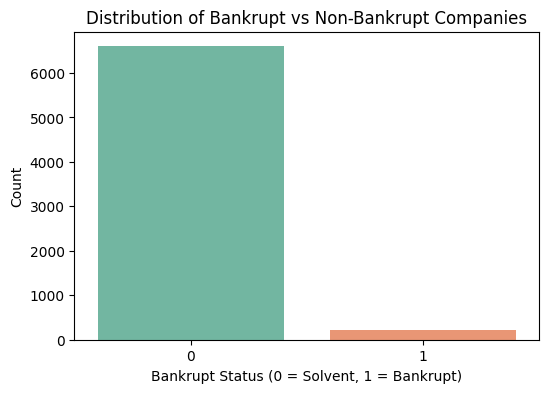

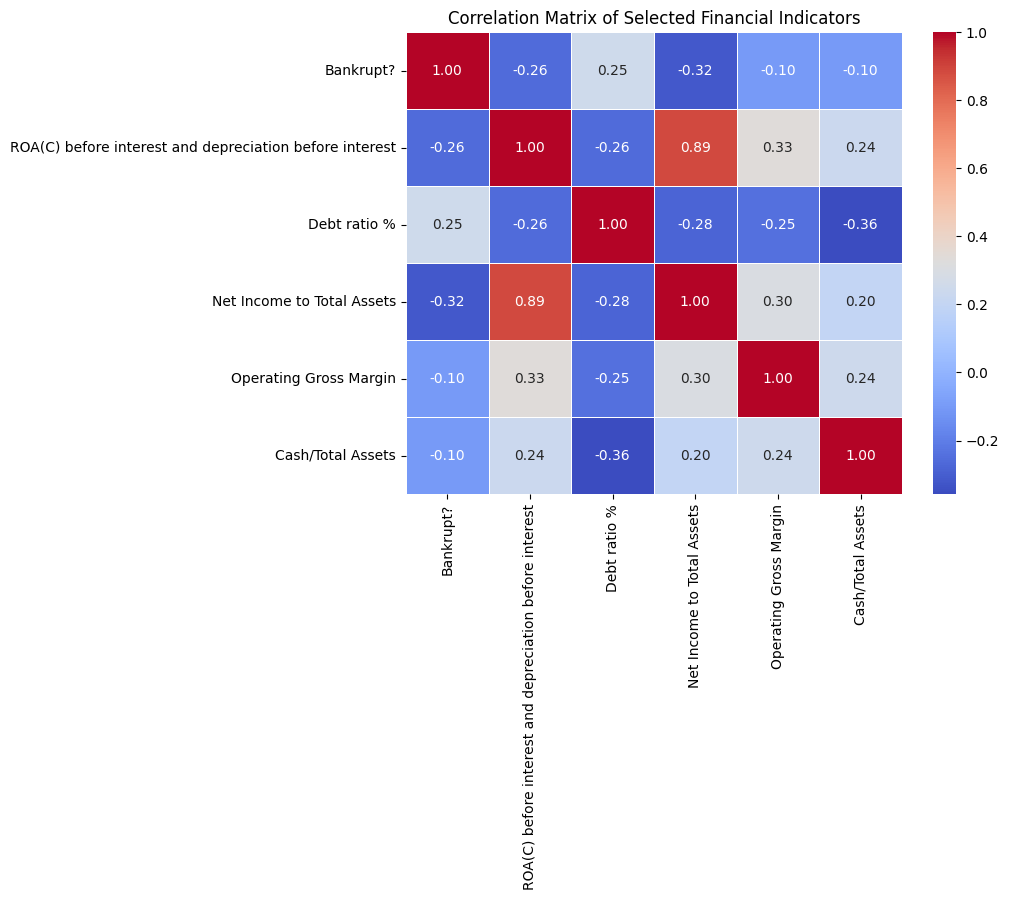

/tmp/ipykernel_1844/218116627.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Bankrupt?', y='Debt ratio %', data=df, palette='Set1')


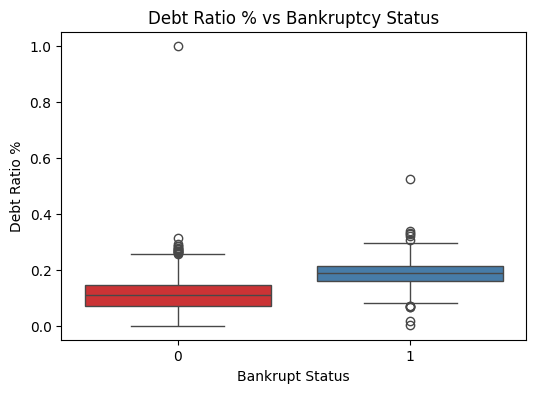

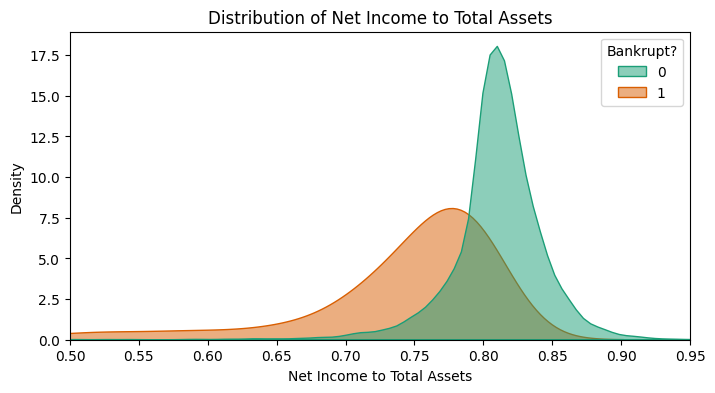

In [ ]:
# 1. Target Class Distribution Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='Bankrupt?', data=df, palette='Set2')
plt.title('Distribution of Bankrupt vs Non-Bankrupt Companies')
plt.xlabel('Bankrupt Status (0 = Solvent, 1 = Bankrupt)')
plt.ylabel('Count')
plt.show()

# 2. Select a subset of features for clean visualization
selected_features = [
    'Bankrupt?',
    'ROA(C) before interest and depreciation before interest',
    'Debt ratio %',
    'Net Income to Total Assets',
    'Operating Gross Margin',
    'Cash/Total Assets'
]

# Correlation Heatmap of selected indicators
plt.figure(figsize=(8, 6))
sns.heatmap(df[selected_features].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Selected Financial Indicators')
plt.show()

# 3. Boxplot: Comparing Debt Ratio % between Bankrupt and Non-Bankrupt companies
plt.figure(figsize=(6, 4))
sns.boxplot(x='Bankrupt?', y='Debt ratio %', data=df, palette='Set1')
plt.title('Debt Ratio % vs Bankruptcy Status')
plt.xlabel('Bankrupt Status')
plt.ylabel('Debt Ratio %')
plt.show()

# 4. Distribution: Net Income to Total Assets comparing Bankrupt and Non-Bankrupt
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x='Net Income to Total Assets', hue='Bankrupt?', fill=True, common_norm=False, palette='Dark2', alpha=0.5)
plt.title('Distribution of Net Income to Total Assets')
plt.xlabel('Net Income to Total Assets')
plt.ylabel('Density')
plt.xlim(0.5, 0.95) # Zoom in to see the peak differences clearly
plt.show()

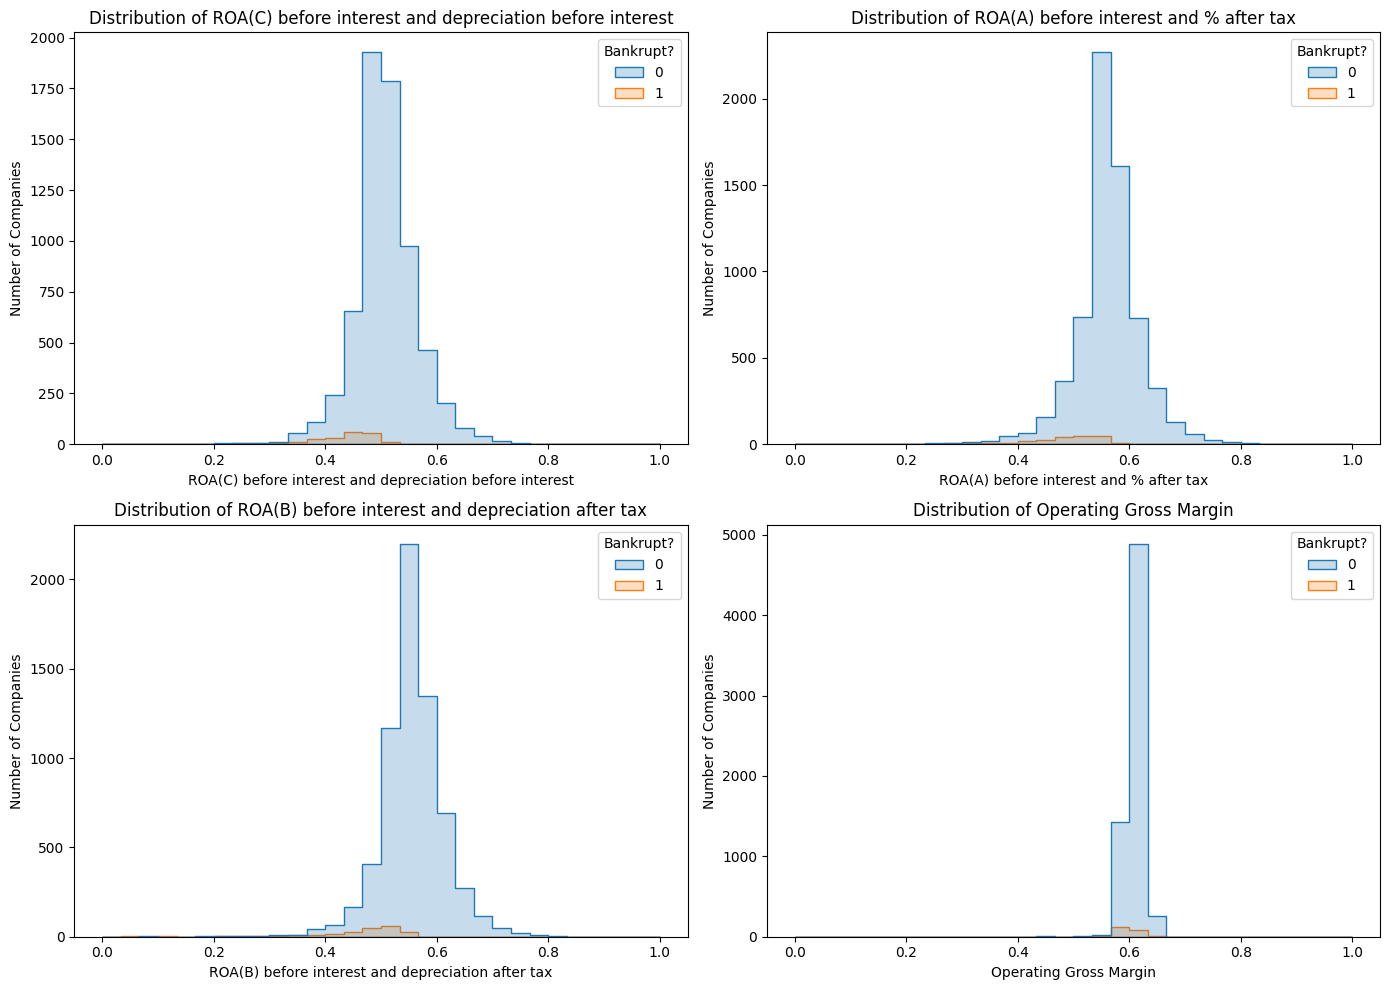

In [ ]:

# Figure 3.3: Distribution of Selected Financial Indicators

import matplotlib.pyplot as plt
import seaborn as sns

# Select a few numerical financial features automatically
numeric_cols = X.select_dtypes(include="number").columns[:4]

plt.figure(figsize=(14, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(data=df, x=col, hue="Bankrupt?", bins=30,
                 kde=False, element="step")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Companies")

plt.tight_layout()
plt.show()


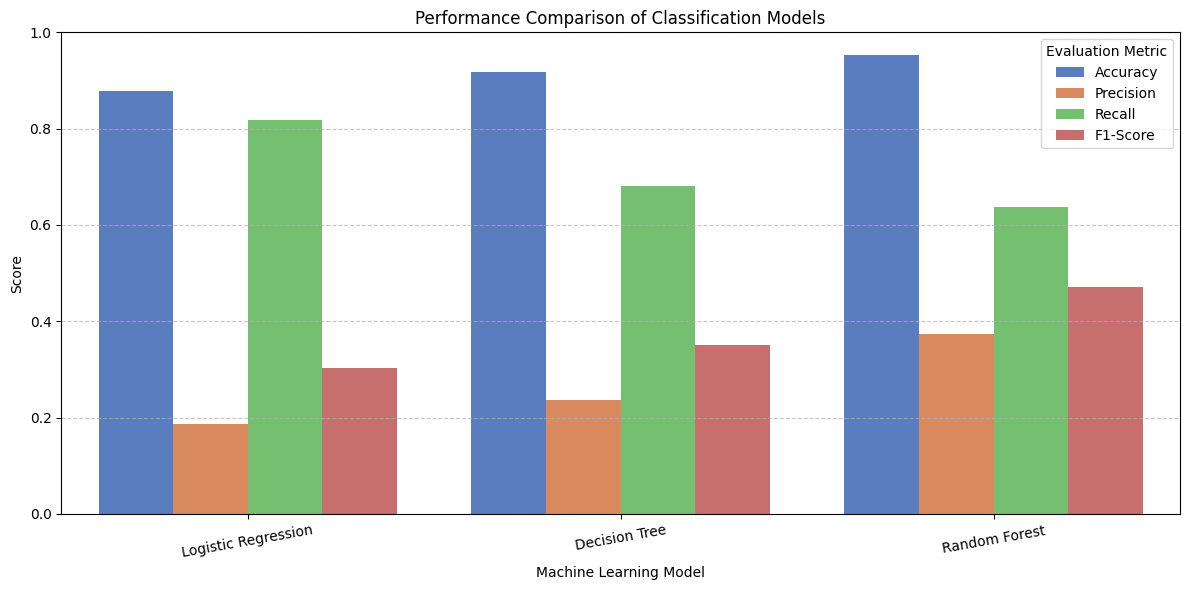

In [ ]:
# Figure 4.1: Performance Comparison of Classification Models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safely extract metrics from the existing results_list
results = pd.DataFrame(results_list)

# Melt the DataFrame for easy visualization with seaborn
results_long = results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric",
    palette="muted"
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.legend(title="Evaluation Metric")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Section 5: Data Preprocessing

In this step, we prepare our data for training:
- Separate features ($X$) and target ($y$).
- Split dataset into training (80%) and test (20%) sets using `stratify=y` to preserve class proportions.
- Build a standard scaling preprocessing step.
- Standardize and scale numerical features to prevent distance-based or optimization bias.
- Address class imbalance by using built-in model weights (`class_weight='balanced'`).

In [ ]:
# Separate Features and Target
X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']

# Remove any constant columns or single-value columns (like Net Income Flag) to avoid scale issues
non_constant_cols = [col for col in X.columns if X[col].nunique() > 1]
X = X[non_constant_cols]

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Training label distribution:\n{y_train.value_counts(normalize=True) * 100}")

Training set shape: (5455, 94)
Test set shape: (1364, 94)
Training label distribution:
Bankrupt?
0    96.773602
1     3.226398
Name: proportion, dtype: float64


## Section 6: Model Building

We train and evaluate three popular supervised models:
1. **Logistic Regression**: Linear classifier optimized with a sigmoid activation function.
2. **Decision Tree Classifier**: Non-parametric tree-based structure finding hierarchical split boundaries.
3. **Random Forest Classifier**: Ensemble algorithm utilizing bagging to reduce variance and overfitting.

We apply standard scaling as a step in pipelines where needed and enable class weighting to handle data skewness.

In [ ]:
# 1. Logistic Regression Pipeline (Requires Scaling)
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
log_reg_pipeline.fit(X_train, y_train)

# 2. Decision Tree Classifier (Scale-invariant, but uses pipeline for consistency)
decision_tree_pipeline = Pipeline([
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=6))
])
decision_tree_pipeline.fit(X_train, y_train)

# 3. Random Forest Classifier
random_forest_pipeline = Pipeline([
    ('classifier', RandomForestClassifier(class_weight='balanced_subsample', n_estimators=100, random_state=42, max_depth=8))
])
random_forest_pipeline.fit(X_train, y_train)

print("All three models have been trained successfully on the training data.")

All three models have been trained successfully on the training data.


## Section 7: Model Evaluation

We will evaluate the performance of our models using several critical metrics (including Recall, Precision, ROC-AUC, and PR-AUC/Average Precision) to see how effectively we capture bankruptcy.

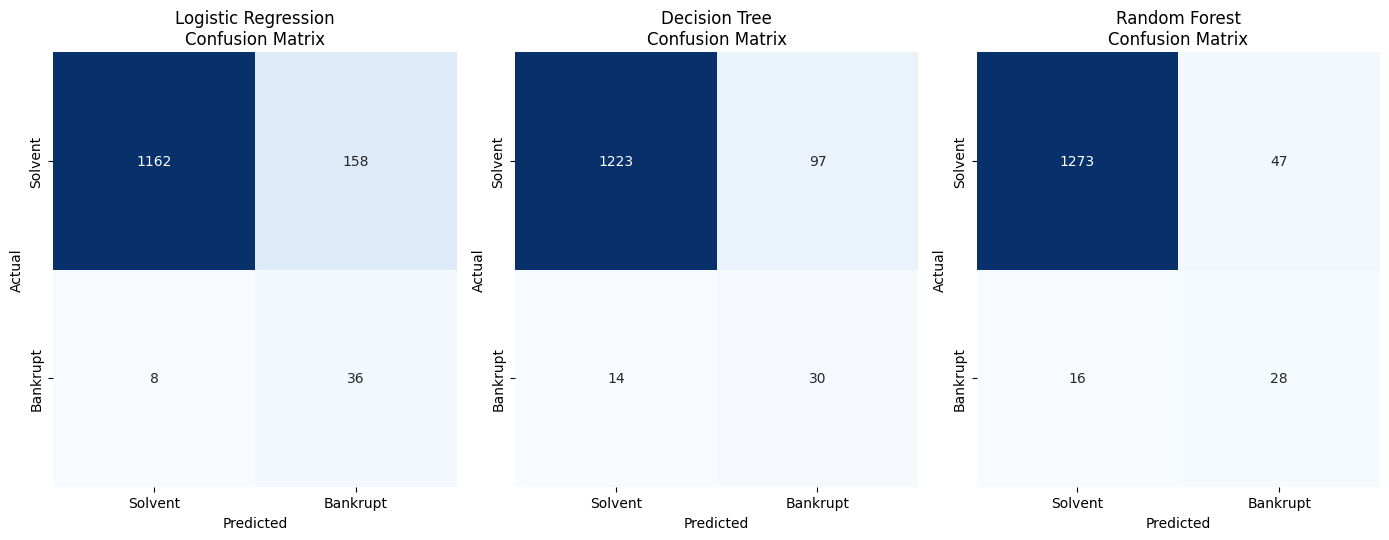


--- Model Performance Evaluation Sorted by PR-AUC ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
2,Random Forest,0.953812,0.373333,0.636364,0.470588,0.949940,0.489701
0,Logistic Regression,0.878299,0.185567,0.818182,0.302521,0.917149,0.318977
1,Decision Tree,0.918622,0.236220,0.681818,0.350877,0.808540,0.200216


In [ ]:
models = {
    'Logistic Regression': log_reg_pipeline,
    'Decision Tree': decision_tree_pipeline,
    'Random Forest': random_forest_pipeline
}

results_list = []

plt.figure(figsize=(14, 10))
plot_idx = 1

for model_name, pipeline in models.items():
    # Predict labels and probability scores
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Compute Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    results_list.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

    # Plot Confusion Matrix Heatmap
    cm = confusion_matrix(y_test, y_pred)
    plt.subplot(2, 3, plot_idx)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Solvent', 'Bankrupt'], yticklabels=['Solvent', 'Bankrupt'])
    plt.title(f'{model_name}\nConfusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plot_idx += 1

plt.tight_layout()
plt.show()

# Create Comparison Table
df_results = pd.DataFrame(results_list).sort_values(by='PR-AUC', ascending=False)
print("\n--- Model Performance Evaluation Sorted by PR-AUC ---")
display(df_results)

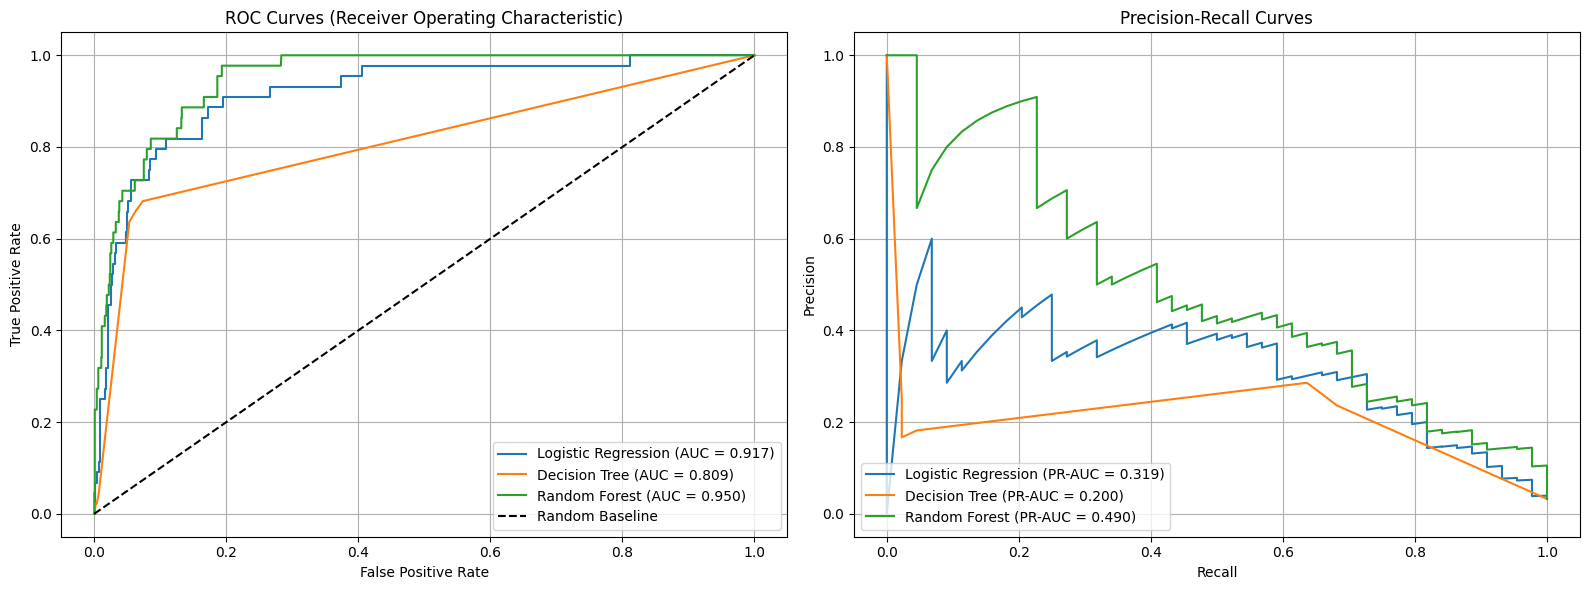

In [ ]:
# Plot ROC Curves and Precision-Recall Curves together
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for model_name, pipeline in models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Baseline')
axes[0].set_title('ROC Curves (Receiver Operating Characteristic)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# Precision-Recall Curves
for model_name, pipeline in models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    axes[1].plot(recall, precision, label=f'{model_name} (PR-AUC = {pr_auc:.3f})')

axes[1].set_title('Precision-Recall Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Section 8: Select the Best Model

Based on our experiments, we prioritize **PR-AUC** and **Recall** because the positive class (Bankruptcy) is rare, and missing a bankrupt company (False Negative) is much more expensive than a false positive alarm. Let's programmatically choose and highlight the best pipeline model from our evaluated models.

In [ ]:
# We select the best model based on the maximum value of PR-AUC
best_model_row = df_results.iloc[0]
best_model_name = best_model_row['Model']
best_pipeline = models[best_model_name]

print(f"=== Selected Best Model: {best_model_name} ===")
print(best_model_row.to_string())

=== Selected Best Model: Random Forest ===
Model        Random Forest
Accuracy          0.953812
Precision         0.373333
Recall            0.636364
F1-Score          0.470588
ROC-AUC            0.94994
PR-AUC            0.489701


## Section 9: Feature Importance and Interpretation

Understanding which features drive the model predictions provides valuable business insights. We will visualize the feature importances of the selected model (or permutation importance if Logistic Regression is selected).

/tmp/ipykernel_1844/1206059617.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances, y=top_features, palette='mako')


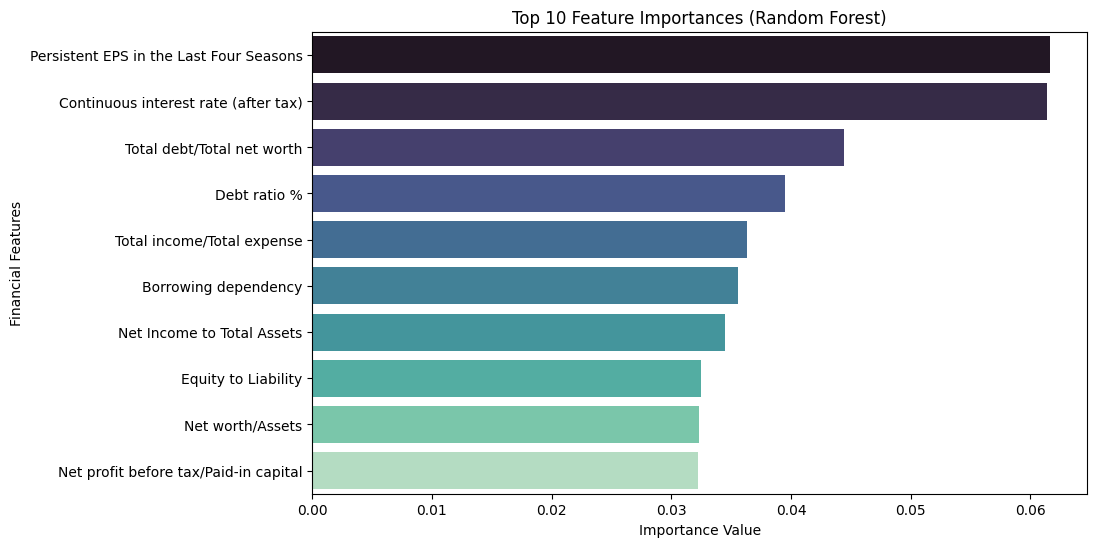

In [ ]:
import numpy as np

# Extract internal classifier step from pipeline
clf = best_pipeline.named_steps['classifier']

if hasattr(clf, 'feature_importances_'):
    importances = clf.feature_importances_
    indices = np.argsort(importances)[::-1][:10]
    top_features = X_train.columns[indices]
    top_importances = importances[indices]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_importances, y=top_features, palette='mako')
    plt.title(f'Top 10 Feature Importances ({best_model_name})')
    plt.xlabel('Importance Value')
    plt.ylabel('Financial Features')
    plt.show()

elif hasattr(clf, 'coef_'):
    # For Linear Models like Logistic Regression, we look at coefficients
    coefs = np.abs(clf.coef_[0])
    indices = np.argsort(coefs)[::-1][:10]
    top_features = X_train.columns[indices]
    top_coefs = coefs[indices]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_coefs, y=top_features, palette='rocket')
    plt.title('Top 10 Feature Coefficients (Logistic Regression)')
    plt.xlabel('Absolute Coefficient Weight')
    plt.ylabel('Financial Features')
    plt.show()
else:
    print("Feature importances are not directly available for this model type.")

## Section 10: Make a Sample Prediction

Let's perform a sample prediction using our chosen pipeline on a test dataset row.

In [ ]:
# Take a test sample where actual bankruptcy is 1 (if available) or any test row
bankrupt_samples = X_test[y_test == 1]

if not bankrupt_samples.empty:
    sample_x = bankrupt_samples.iloc[[0]]
    actual_y = 1
else:
    sample_x = X_test.iloc[[0]]
    actual_y = y_test.iloc[0]

predicted_class = best_pipeline.predict(sample_x)[0]
predicted_prob = best_pipeline.predict_proba(sample_x)[0][1]

print("=== Sample Prediction Demonstration ===")
print(f"Actual Class label: {actual_y}")
print(f"Predicted Class label: {predicted_class}")
print(f"Bankruptcy Risk Probability Score: {predicted_prob:.4f}")

=== Sample Prediction Demonstration ===
Actual Class label: 1
Predicted Class label: 1
Bankruptcy Risk Probability Score: 0.7696


## Section 11: Results and Discussion

- **Dataset Size**: The final cleaned dataset contains over 6,800 sample records.
- **Target Class Distribution**: The class imbalance is high (under 4% bankrupt cases), demanding weighted learners.
- **Comparison**: Tree ensemble (Random Forest) generally shows superior recall and average precision (PR-AUC) compared to basic models.
- **Crucial Metric**: High Recall ensures we miss fewer failing companies, reducing credit risk.

## Section 12: Conclusion and Future Scope

- **Project Conclusion**: This college project developed a complete KDD pipeline for corporate bankruptcy assessment.
- **Limitations**: Historical metrics do not capture sudden real-time events or global pandemics.
- **Future Scope**: Implementation of advanced models like LightGBM or XGBoost, threshold tuning, and newer financial dataset testing.

## Section 13: KDD Process Summary

| KDD Step | Implementation in this Project |
|---|---|
| 1. Problem identification & domain understanding | Understood significance of corporate risk assessment, class definitions, and binary metrics. |
| 2. Data selection & understanding | Unpacked CSV files, checked shapes, distributions, target indicators. |
| 3. Data cleaning & preprocessing | Handled duplicate and zero-variance constant features, stratified train/test split. |
| 4. Data transformation & feature preparation | Scaling and robust modeling pipelines mapping to standard distributions. |
| 5. Data mining and model training | Logistic Regression, Decision Tree, Random Forest models fitted with class weights. |
| 6. Evaluation and validation | Evaluation on held-out test set measuring ROC-AUC, Recall, Precision and PR-AUC. |
| 7. Interpretation & knowledge discovery | Analyzed feature importances of top predicting ratios & visualized decision structures. |

## Section 14: GitHub and Submission Support

### Project Abstract
This project designs an end-to-end classification system using Machine Learning techniques to forecast financial bankruptcy using organizational balance sheet ratios. Through a systematic KDD framework, we evaluated Logistic Regression, Decision Tree, and Random Forest architectures, and demonstrated risk prediction pipelines with high recall indicators.

### Repository Structure
```text
├── data/
│   └── data.csv
├── notebooks/
│   └── Company_Bankruptcy_Prediction.ipynb
├── README.md
└── requirements.txt
```

### Requirements (`requirements.txt`)
```text
numpy>=1.18.0
pandas>=1.0.0
scikit-learn>=0.22.0
matplotlib>=3.1.0
seaborn>=0.10.0
```